# Qwen: revised probe instructions test

This notebook reports a protocol pilot on the deliberately damaged **handcrafted calibration model**, not the harder learned checkpoint. Qwen receives separate conversations for weights-only, fixed probes, and adaptive probes. The purpose is to test whether the revised turn instructions lead to valid responses; repair accuracy is a secondary calibration check.

In [1]:
from pathlib import Path
import json
import matplotlib.pyplot as plt
ROOT=Path.cwd().resolve()
if not (ROOT/'experiment.json').exists(): ROOT=ROOT.parent
path=ROOT/'results/qwen_v3_protocol_test.json'
if not path.exists(): raise FileNotFoundError('The Qwen v3 calibration is not complete yet.')
report=json.loads(path.read_text()); sessions=report['sessions']
OUT=ROOT/'results/figures';OUT.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'figure.dpi':110,'savefig.dpi':300,'axes.spines.top':False,'axes.spines.right':False})
def save(fig,name):
    fig.savefig(OUT/f'{name}.png',bbox_inches='tight',facecolor='white')
    fig.savefig(OUT/f'{name}.svg',bbox_inches='tight',facecolor='white')

## Did the protocol work?

A completed weights-only session returns an edit immediately. A completed fixed or adaptive session supplies four batches of eight probes and then a valid edit. An incomplete session is shown as missing, not a zero score.

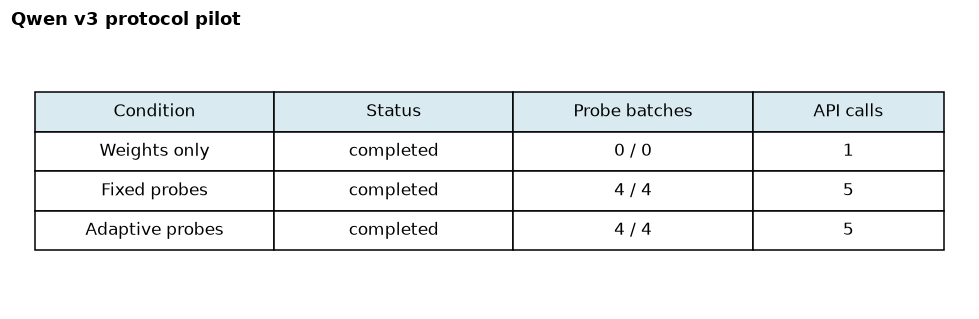

In [2]:
labels={'weights_only':'Weights only','fixed_probes':'Fixed probes','adaptive_probes':'Adaptive probes'}
rows=[[labels[s['condition']],s['status'],str(s['probe_rounds'])+' / '+('0' if s['condition']=='weights_only' else '4'),str(s['calls'])] for s in sessions]
fig,ax=plt.subplots(figsize=(9,3));ax.axis('off');t=ax.table(cellText=rows,colLabels=['Condition','Status','Probe batches','API calls'],loc='center',cellLoc='center',colColours=['#d9ebf1']*4,colWidths=[.25,.25,.25,.2]);t.auto_set_font_size(False);t.set_fontsize(11);t.scale(1,2);ax.set_title('Qwen v3 protocol pilot',loc='left',fontweight='bold');fig.tight_layout();save(fig,'32_qwen_v3_protocol');plt.show()
for s in sessions:
    if s['status']!='completed':print(labels[s['condition']], 'incomplete:',s.get('reason','not specified'))

## Calibration edit results

The same handcrafted model is used for each session. Accuracy is measured on a development sample after each valid proposal is frozen. This controlled fault is useful for checking the workflow, but it does not predict how well Qwen will repair the harder trained checkpoint.

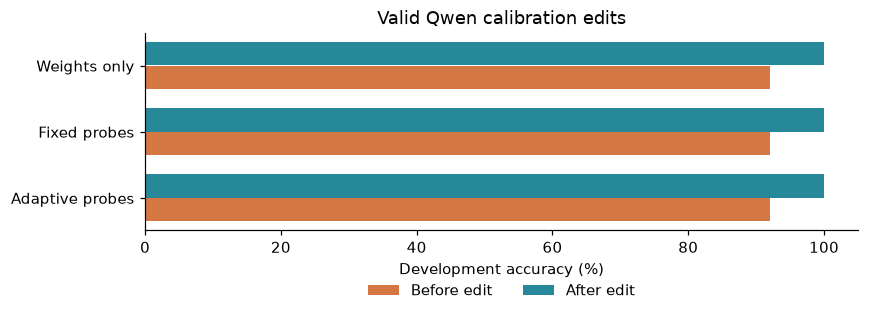

Weights only edit: {'parameter': 'fc2.weight', 'index': [0, 0], 'scale': 2.0}
Fixed probes edit: {'parameter': 'fc2.weight', 'index': [0, 0], 'scale': 2.0}
Adaptive probes edit: {'parameter': 'fc2.weight', 'index': [0, 0], 'scale': 2.0}


In [3]:
complete=[s for s in sessions if s['status']=='completed']
if complete:
    import numpy as np
    y=np.arange(len(complete));before=[s['validation']['before']['accuracy']*100 for s in complete];after=[s['validation']['after']['accuracy']*100 for s in complete]
    fig,ax=plt.subplots(figsize=(8,max(2.5,len(complete)*.7+1)));ax.barh(y+.18,before,.35,label='Before edit',color='#d47743');ax.barh(y-.18,after,.35,label='After edit',color='#27889a');ax.set(yticks=y,yticklabels=[labels[s['condition']] for s in complete],xlim=(0,105),xlabel='Development accuracy (%)',title='Valid Qwen calibration edits');ax.invert_yaxis();ax.legend(frameon=False,loc='upper center',bbox_to_anchor=(.5,-.2),ncol=2);fig.tight_layout();save(fig,'33_qwen_v3_calibration_accuracy');plt.show()
    for s in complete:print(labels[s['condition']], 'edit:',s['edit'])
else: print('No valid final proposals to score.')

## Limits

The pilot uses one session per condition and the same small calibration circuit used in earlier testing. A valid format does not establish that an explanation is correct or that probes caused a better edit. Output-token reports and costs are recorded in the private provider journals. The new learned-checkpoint study has not been evaluated as part of this pilot.